In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Supervised_Learning_Messy_Customer_Churn.csv")

df.head()


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,MONTHLY,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,NaN,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [47]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1]) 

Number of Rows: 184
Number of Columns: 13


In [48]:
df.head()

,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,MONTHLY,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,NaN,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [49]:
df.tail()

,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
179,CUST-1107,55.0,54100.0,68.0,99.59,6.0,21.5,8.0,1 Year,Bank Transfer,East,Basic,Yes
180,CUST-1015,19.0,63000.0,NaN,64.24,1.0,13.0,7.0,Monthly,Credit Card,south,Premium,Yes
181,CUST-1093,29.0,45300.0,69.0,67.48,1.0,10.6,6.0,Monthly,Debit Card,East,Standard,No
182,CUST-1180,63.0,47100.0,45.0,65.58,0.0,11.3,1.0,Monthly,UPI,East,Standard,Yes
183,CUST-1103,NaN,48300.0,13.0,94.69,0.0,16.8,1.0,2 Year,Bank Transfer,West,Standard,No


In [50]:
print("All the columns:- \n \t", df.columns.tolist()) 
print("-" * 50) 
print(" " * 50) 
print( "Categorical columns:- \n \t" , df.select_dtypes(include = ["category", "object"]).columns.tolist())
print("-" * 50) 
print(" " * 50) 
print( "Numerical columns:- \n \t" , df.select_dtypes(include = ["number"]).columns.tolist()) 
print("-" * 50) 
print(" " * 50) 
print(" " * 50) 

All the columns:- 
 	 ['Customer_ID', 'Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type', 'Churn']
--------------------------------------------------
                                                  
Categorical columns:- 
 	 ['Customer_ID', 'Annual_Income', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type', 'Churn']
--------------------------------------------------
                                                  
Numerical columns:- 
 	 ['Age', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score']
--------------------------------------------------
                                                  
                                                  


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20632\1649015166.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print( "Categorical columns:- \n \t" , df.select_dtypes(include = ["category", "object"]).columns.tolist())


In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            184 non-null    str    
 1   Age                    176 non-null    float64
 2   Annual_Income          173 non-null    str    
 3   Tenure_Months          177 non-null    float64
 4   Monthly_Charges        178 non-null    float64
 5   Support_Calls_Last_3M  179 non-null    float64
 6   Data_Usage_GB          178 non-null    float64
 7   Satisfaction_Score     178 non-null    float64
 8   Contract_Type          184 non-null    str    
 9   Payment_Method         184 non-null    str    
 10  Region                 184 non-null    str    
 11  Plan_Type              184 non-null    str    
 12  Churn                  184 non-null    str    
dtypes: float64(6), str(7)
memory usage: 27.0 KB


In [52]:
df.describe()

,Age,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score
count,176.000000,177.000000,178.000000,179.000000,178.000000,178.000000
mean,36.164773,39.395480,80.205899,3.217877,17.806180,5.803371
std,12.865951,21.545185,74.179370,2.577455,9.245516,2.947869
min,-5.000000,1.000000,0.000000,0.000000,-10.000000,1.000000
25%,29.000000,25.000000,57.885000,2.000000,11.600000,4.000000
50%,36.000000,38.000000,73.565000,3.000000,18.200000,6.000000
75%,41.000000,55.000000,90.280000,4.000000,24.200000,8.000000
max,145.000000,150.000000,999.000000,30.000000,44.000000,15.000000


In [53]:
df.describe(include="object")

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20632\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Customer_ID,Annual_Income,Contract_Type,Payment_Method,Region,Plan_Type,Churn
count,184,173,184,184,184,184,184
unique,180,156,8,9,8,6,2
top,CUST-1043,76600.0,Monthly,Bank Transfer,South,Standard,Yes
freq,2,4,104,48,50,93,97


In [54]:
# Check missing values and duplicate records 

missing_values = df.isnull().sum()

print(missing_values)

print("-------------------------------------------------") 

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print(missing_percentage)

Customer_ID               0
Age                       8
Annual_Income            11
Tenure_Months             7
Monthly_Charges           6
Support_Calls_Last_3M     5
Data_Usage_GB             6
Satisfaction_Score        6
Contract_Type             0
Payment_Method            0
Region                    0
Plan_Type                 0
Churn                     0
dtype: int64
-------------------------------------------------
Customer_ID              0.00
Age                      4.35
Annual_Income            5.98
Tenure_Months            3.80
Monthly_Charges          3.26
Support_Calls_Last_3M    2.72
Data_Usage_GB            3.26
Satisfaction_Score       3.26
Contract_Type            0.00
Payment_Method           0.00
Region                   0.00
Plan_Type                0.00
Churn                    0.00
dtype: float64


In [55]:
# Check duplicate records 

print("Duplicate Rows:", df.duplicated().sum())
print("---------------------------------------------------------------") 
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())

Duplicate Rows: 4
---------------------------------------------------------------
Duplicate Customer IDs: 4


In [56]:
# Inspect categorical values 

categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20632\1596224560.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(



Customer_ID:
<ArrowStringArray>
['CUST-1020', 'CUST-1043', 'CUST-1157', 'CUST-1112', 'CUST-1149', 'CUST-1016',
 'CUST-1025', 'CUST-1069', 'CUST-1118', 'CUST-1099',
 ...
 'CUST-1088', 'CUST-1075', 'CUST-1122', 'CUST-1021', 'CUST-1072', 'CUST-1107',
 'CUST-1015', 'CUST-1093', 'CUST-1180', 'CUST-1103']
Length: 180, dtype: str

Annual_Income:
<ArrowStringArray>
[ '23800.0',  '69400.0',        nan,  '80000.0',  '95700.0',  '88000.0',
  '49100.0',  '69200.0',  '43300.0',  '59800.0',
 ...
  '54200.0',  '37900.0',  '71300.0',  '79200.0', '100400.0',  '54100.0',
  '63000.0',  '45300.0',  '47100.0',  '48300.0']
Length: 157, dtype: str

Contract_Type:
<ArrowStringArray>
['MONTHLY', 'Monthly', '1 Year', '2 Year', '2-Year', '1 year', 'monthly', '?']
Length: 8, dtype: str

Payment_Method:
<ArrowStringArray>
['Bank Transfer',           'UPI',    'Debit Card',   'Credit Card',
             '?', 'bank transfer',           'upi',       'Unknown',
   'Credit card']
Length: 9, dtype: str

Region:
<ArrowS

In [57]:
# Inspect suspicious numerical values 

print(df["Annual_Income"].unique())

<ArrowStringArray>
[ '23800.0',  '69400.0',        nan,  '80000.0',  '95700.0',  '88000.0',
  '49100.0',  '69200.0',  '43300.0',  '59800.0',
 ...
  '54200.0',  '37900.0',  '71300.0',  '79200.0', '100400.0',  '54100.0',
  '63000.0',  '45300.0',  '47100.0',  '48300.0']
Length: 157, dtype: str


In [58]:
# Check numerical minimum and maximum 

numeric_columns = df.select_dtypes(
    include="number"
).columns

for column in numeric_columns:
    print(
        f"{column}: "
        f"Min = {df[column].min()}, "
        f"Max = {df[column].max()}"
    )

Age: Min = -5.0, Max = 145.0
Tenure_Months: Min = 1.0, Max = 150.0
Monthly_Charges: Min = 0.0, Max = 999.0
Support_Calls_Last_3M: Min = 0.0, Max = 30.0
Data_Usage_GB: Min = -10.0, Max = 44.0
Satisfaction_Score: Min = 1.0, Max = 15.0


In [59]:
identifier_columns = ["Customer_ID"]

target_column = "Churn"

print("Identifier Columns:", identifier_columns)
print("Target Column:", target_column)

Identifier Columns: ['Customer_ID']
Target Column: Churn


In [60]:
df_clean = df.copy()

print("Original Shape:", df.shape)
print("Working Shape:", df_clean.shape)

Original Shape: (184, 13)
Working Shape: (184, 13)


In [61]:
# Replace placeholder values 

df_clean.replace(
    to_replace=r"^\s*(NA|N/A|\?|)$",             # A regular expression that identifies placeholders.
    value=np.nan,                                # Replaces matched values with a proper missing value.
    regex=True,                                  # Tells Pandas to interpret the pattern as a regular expression.
    inplace=True                                 # Modifies df_clean directly.
)

print("Placeholder values converted to NaN.")

Placeholder values converted to NaN.


In [62]:
# Check missing values 

missing_summary = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

print(missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
))

print("-" * 50)
print(
    "Rows with Missing Values:",
    df_clean.isnull().any(axis=1).sum() )

                       Missing_Count  Missing_Percentage
Annual_Income                     12                6.52
Age                                8                4.35
Tenure_Months                      7                3.80
Monthly_Charges                    6                3.26
Data_Usage_GB                      6                3.26
Satisfaction_Score                 6                3.26
Support_Calls_Last_3M              5                2.72
Payment_Method                     1                0.54
Contract_Type                      1                0.54
Region                             1                0.54
Customer_ID                        0                0.00
Plan_Type                          0                0.00
Churn                              0                0.00
--------------------------------------------------
Rows with Missing Values: 44


In [63]:
# Duplicate Records 

# Check exact duplicate records 

print("Exact Duplicate Rows:", df_clean.duplicated().sum()) 

duplicates = df_clean[
    df_clean.duplicated(keep=False)
]

duplicates.sort_values("Customer_ID")

Exact Duplicate Rows: 4


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
132,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
154,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
119,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
46,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
71,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
169,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No
176,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No


In [64]:
# Check repeated Customer IDs

print(
    "Duplicate Customer IDs:",
    df_clean["Customer_ID"].duplicated().sum()
)

repeated_customers = df_clean[
    df_clean["Customer_ID"].duplicated(keep=False)
].sort_values("Customer_ID")

repeated_customers

Duplicate Customer IDs: 4


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
132,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
154,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
119,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
46,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
71,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
169,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No
176,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No


In [65]:
df_clean = df_clean.drop_duplicates(keep="first")

print("Dataset Shape:", df_clean.shape)
print("Exact Duplicate Rows:", df_clean.duplicated().sum())

Dataset Shape: (180, 13)
Exact Duplicate Rows: 0


In [66]:
# Check categorical inconsistencies 

cat_cols = [
    "Contract_Type",
    "Payment_Method",
    "Region",
    "Plan_Type",
    "Churn"
]

for col in cat_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False))


Contract_Type:
Contract_Type
Monthly    101
1 Year      51
2 Year      23
MONTHLY      1
2-Year       1
1 year       1
monthly      1
NaN          1
Name: count, dtype: int64

Payment_Method:
Payment_Method
UPI              46
Bank Transfer    45
Credit Card      43
Debit Card       41
NaN               1
bank transfer     1
upi               1
Unknown           1
Credit card       1
Name: count, dtype: int64

Region:
Region
North     49
South     48
West      45
East      34
west       1
NORTH      1
NaN        1
south      1
Name: count, dtype: int64

Plan_Type:
Plan_Type
Standard     93
Basic        46
Premium      38
basic         1
premium       1
STANDARD      1
Name: count, dtype: int64

Churn:
Churn
Yes    94
No     86
Name: count, dtype: int64


In [67]:
# Checking and handling categorical inconsistencies 

# Remove leading and trailing spaces
cat_cols = [
    "Contract_Type",
    "Payment_Method",
    "Region",
    "Plan_Type",
    "Churn"
]

for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()

# Standardize Contract_Type
df_clean["Contract_Type"] = df_clean["Contract_Type"].replace({
    "MONTHLY": "Monthly",
    "monthly": "Monthly",
    "1 year": "1 Year",
    "2-Year": "2 Year"
})

# Standardize Payment_Method
df_clean["Payment_Method"] = df_clean["Payment_Method"].replace({
    "bank transfer": "Bank Transfer",
    "upi": "UPI",
    "Credit card": "Credit Card",
    "Unknown": np.nan
}) 

print(df_clean["Contract_Type"].value_counts(dropna=False))
print("----------------------------------------------------")
print(df_clean["Payment_Method"].value_counts(dropna=False))
print("----------------------------------------------------")

Contract_Type
Monthly    103
1 Year      52
2 Year      24
NaN          1
Name: count, dtype: int64
----------------------------------------------------
Payment_Method
UPI              47
Bank Transfer    46
Credit Card      44
Debit Card       41
NaN               2
Name: count, dtype: int64
----------------------------------------------------


In [68]:
# Standardize Region values
df_clean["Region"] = df_clean["Region"].str.strip().str.title()

# Verify
print(df_clean["Region"].value_counts(dropna=False))

Region
North    50
South    49
West     46
East     34
NaN       1
Name: count, dtype: int64


In [69]:
# Standardize Plan_Type values
df_clean["Plan_Type"] = df_clean["Plan_Type"].str.strip().str.title()

# Verify
print(df_clean["Plan_Type"].value_counts(dropna=False))

Plan_Type
Standard    94
Basic       47
Premium     39
Name: count, dtype: int64


In [70]:
# Verify target labels
print(df_clean["Churn"].value_counts(dropna=False))
print("\nUnique values:", df_clean["Churn"].unique())

Churn
Yes    94
No     86
Name: count, dtype: int64

Unique values: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


In [71]:
# Numerical Data Cleaning 

# Annual_Income 

print("Data Type:", df_clean["Annual_Income"].dtype)

print("\nUnique Values:")
print(df_clean["Annual_Income"].value_counts(dropna=False).head(20))

Data Type: str

Unique Values:
Annual_Income
NaN         12
76600.0      3
76800.0      2
64700.0      2
45700.0      2
67400.0      2
78200.0      2
50800.0      2
100000.0     2
53000.0      2
59300.0      2
62300.0      2
75100.0      2
23800.0      1
69400.0      1
80000.0      1
95700.0      1
88000.0      1
49100.0      1
69200.0      1
Name: count, dtype: int64


In [72]:
# Convert Annual_Income from string to numeric

df_clean["Annual_Income"] = pd.to_numeric(
    df_clean["Annual_Income"],
    errors="coerce"
)

# Verify data type
print("Data Type:", df_clean["Annual_Income"].dtype)

# Verify missing values
print("Missing Values:", df_clean["Annual_Income"].isna().sum())

# Verify numerical summary
print("\nStatistical Summary:")
print(df_clean["Annual_Income"].describe())

Data Type: float64
Missing Values: 12

Statistical Summary:
count    1.680000e+02
mean     1.234518e+05
std      7.669285e+05
min     -1.200000e+04
25%      4.900000e+04
50%      6.440000e+04
75%      7.820000e+04
max      9.999999e+06
Name: Annual_Income, dtype: float64


In [73]:
# Identify suspicious income records

# Inspect negative income values
print("Negative Annual Income:")

display(
    df_clean[df_clean["Annual_Income"] < 0][
        ["Customer_ID", "Annual_Income", "Churn"]
    ]
)

# Inspect the 10 highest income values
print("\nTop 10 Annual Income Values:")
display(
    df_clean.nlargest(10, "Annual_Income")[
        ["Customer_ID", "Annual_Income", "Churn"]
    ]
)

Negative Annual Income:


,Customer_ID,Annual_Income,Churn
95,CUST-1143,-11500.0,No
112,CUST-1062,-12000.0,Yes



Top 10 Annual Income Values:


,Customer_ID,Annual_Income,Churn
96,CUST-1026,9999999.0,No
44,CUST-1148,120900.0,Yes
61,CUST-1177,116500.0,Yes
163,CUST-1158,110200.0,Yes
102,CUST-1040,109500.0,Yes
136,CUST-1162,108100.0,Yes
82,CUST-1011,107900.0,No
161,CUST-1130,107100.0,No
20,CUST-1165,106900.0,Yes
54,CUST-1047,104900.0,No


In [74]:
# Replace invalid Annual_Income values with NaN

df_clean.loc[
    df_clean["Annual_Income"] < 0,
    "Annual_Income"
] = np.nan

df_clean.loc[
    df_clean["Annual_Income"] == 9999999,
    "Annual_Income"
] = np.nan

# Verify
print("Missing Annual Income:", df_clean["Annual_Income"].isna().sum())

print("\nUpdated Summary:")
print(df_clean["Annual_Income"].describe())

Missing Annual Income: 15

Updated Summary:
count       165.000000
mean      65232.727273
std       22623.916666
min        8600.000000
25%       49700.000000
50%       64700.000000
75%       78200.000000
max      120900.000000
Name: Annual_Income, dtype: float64


In [75]:
# Handling numerical column - Age 

print("Age Summary:")
print(df_clean["Age"].describe())

print("\nNegative Ages:")
display(
    df_clean[df_clean["Age"] < 0][
        ["Customer_ID", "Age", "Churn"]
    ]
)

print("\nAges Above 100:")
display(
    df_clean[df_clean["Age"] > 100][
        ["Customer_ID", "Age", "Churn"]
    ]
)

Age Summary:
count    172.000000
mean      36.116279
std       12.999252
min       -5.000000
25%       29.000000
50%       36.000000
75%       41.000000
max      145.000000
Name: Age, dtype: float64

Negative Ages:


,Customer_ID,Age,Churn
144,CUST-1018,-5.0,Yes



Ages Above 100:


,Customer_ID,Age,Churn
127,CUST-1004,145.0,No


In [76]:
# Replace negative ages with NaN
df_clean.loc[
    df_clean["Age"] < 0,
    "Age"
] = np.nan

# Replace ages above 100 with NaN
df_clean.loc[
    df_clean["Age"] > 100,
    "Age"
] = np.nan

# Verify
print("Missing Age Values:", df_clean["Age"].isna().sum())

print("\nUpdated Age Summary:")
print(df_clean["Age"].describe())

Missing Age Values: 10

Updated Age Summary:
count    170.000000
mean      35.717647
std        9.521836
min       10.000000
25%       29.000000
50%       36.000000
75%       41.000000
max       63.000000
Name: Age, dtype: float64


In [77]:
# Handling numerical column - Tenure_Months 

# Inspect Tenure_Months

print(df_clean["Tenure_Months"].describe())

print("\nMissing Values:")
print(df_clean["Tenure_Months"].isna().sum())

print("\nUnique Values:")
print(sorted(df_clean["Tenure_Months"].dropna().unique()))


count    173.000000
mean      39.300578
std       21.499104
min        1.000000
25%       25.000000
50%       38.000000
75%       54.000000
max      150.000000
Name: Tenure_Months, dtype: float64

Missing Values:
7

Unique Values:
[np.float64(1.0), np.float64(2.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(17.0), np.float64(18.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np

In [78]:
# Inspect unusually high tenure values

print(
    df_clean.loc[
        df_clean["Tenure_Months"] > 72,
        ["Customer_ID", "Tenure_Months", "Contract_Type", "Churn"]
    ]
)


# Check zero or negative tenure

print(
    df_clean.loc[
        df_clean["Tenure_Months"] <= 0,
        ["Customer_ID", "Tenure_Months", "Churn"]
    ]
)

   Customer_ID  Tenure_Months Contract_Type Churn
40   CUST-1013          150.0        1 Year    No
Empty DataFrame
Columns: [Customer_ID, Tenure_Months, Churn]
Index: []


In [79]:
print("Missing Tenure Values:",
      df_clean["Tenure_Months"].isna().sum())

print(df_clean["Tenure_Months"].describe())

Missing Tenure Values: 7
count    173.000000
mean      39.300578
std       21.499104
min        1.000000
25%       25.000000
50%       38.000000
75%       54.000000
max      150.000000
Name: Tenure_Months, dtype: float64


In [80]:
# Handling numerical column - Monthly_Charges 

# Inspect Monthly_Charges

print(df_clean["Monthly_Charges"].describe())

print("\nMissing Values:")
print(df_clean["Monthly_Charges"].isna().sum())

print("\nHighest Monthly Charges:")
print(
    df_clean.nlargest(10, "Monthly_Charges")[
        ["Customer_ID", "Monthly_Charges", "Plan_Type", "Contract_Type", "Churn"]
    ]
)

print("\nZero or Negative Charges:")
print(
    df_clean.loc[
        df_clean["Monthly_Charges"] <= 0,
        ["Customer_ID", "Monthly_Charges", "Plan_Type", "Churn"]
    ]
)

count    174.000000
mean      79.886207
std       74.970492
min        0.000000
25%       57.457500
50%       72.945000
75%       90.032500
max      999.000000
Name: Monthly_Charges, dtype: float64

Missing Values:
6

Highest Monthly Charges:
    Customer_ID  Monthly_Charges Plan_Type Contract_Type Churn
157   CUST-1089           999.00  Standard        1 Year   Yes
173   CUST-1088           151.18  Standard        1 Year   Yes
114   CUST-1034           140.55  Standard       Monthly    No
144   CUST-1018           137.15   Premium       Monthly   Yes
153   CUST-1051           136.94     Basic       Monthly   Yes
55    CUST-1173           134.89     Basic       Monthly   Yes
18    CUST-1083           134.54  Standard       Monthly    No
92    CUST-1029           126.78     Basic        1 Year    No
93    CUST-1041           123.06     Basic       Monthly    No
127   CUST-1004           120.65   Premium        1 Year    No

Zero or Negative Charges:
   Customer_ID  Monthly_Charges Plan_

In [81]:
# Replace suspicious and invalid monthly charges with NaN

df_clean.loc[
    df_clean["Monthly_Charges"] == 999,
    "Monthly_Charges"
] = np.nan

df_clean.loc[
    df_clean["Monthly_Charges"] == 0,
    "Monthly_Charges"
] = np.nan

# Verify
print("Missing Monthly Charges:",
      df_clean["Monthly_Charges"].isna().sum())

print(df_clean["Monthly_Charges"].describe())

Missing Monthly Charges: 8
count    172.000000
mean      75.006977
std       26.170010
min        9.970000
25%       57.692500
50%       72.945000
75%       89.537500
max      151.180000
Name: Monthly_Charges, dtype: float64


In [82]:
# Handling numerical column - Support_Calls_Last_3M 

print(df_clean["Support_Calls_Last_3M"].describe())

print("\nMissing Values:")
print(df_clean["Support_Calls_Last_3M"].isna().sum())

print("\nHighest Support Calls:")
print(
    df_clean.nlargest(10, "Support_Calls_Last_3M")[
        ["Customer_ID", "Support_Calls_Last_3M", "Churn"]
    ]
)

print("\nNegative Support Calls:")
print(
    df_clean.loc[
        df_clean["Support_Calls_Last_3M"] < 0,
        ["Customer_ID", "Support_Calls_Last_3M", "Churn"]
    ]
)


count    175.000000
mean       3.211429
std        2.594398
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       30.000000
Name: Support_Calls_Last_3M, dtype: float64

Missing Values:
5

Highest Support Calls:
    Customer_ID  Support_Calls_Last_3M Churn
35    CUST-1030                   30.0   Yes
0     CUST-1020                    7.0   Yes
94    CUST-1142                    7.0   Yes
121   CUST-1128                    7.0   Yes
170   CUST-1104                    7.0   Yes
1     CUST-1043                    6.0   Yes
25    CUST-1127                    6.0    No
57    CUST-1086                    6.0    No
73    CUST-1007                    6.0   Yes
109   CUST-1095                    6.0   Yes

Negative Support Calls:
Empty DataFrame
Columns: [Customer_ID, Support_Calls_Last_3M, Churn]
Index: []


In [83]:
print("Missing Support Calls:",
      df_clean["Support_Calls_Last_3M"].isna().sum())

print(df_clean["Support_Calls_Last_3M"].describe())

Missing Support Calls: 5
count    175.000000
mean       3.211429
std        2.594398
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       30.000000
Name: Support_Calls_Last_3M, dtype: float64


In [84]:
# Handling numerical column - Data_Usage_GB 

# Inspect Data_Usage_GB

print(df_clean["Data_Usage_GB"].describe())

print("\nMissing Values:")
print(df_clean["Data_Usage_GB"].isna().sum())

print("\nNegative Data Usage:")
print(
    df_clean.loc[
        df_clean["Data_Usage_GB"] < 0,
        ["Customer_ID", "Data_Usage_GB", "Churn"]
    ]
)

print("\nHighest Data Usage:")
print(
    df_clean.nlargest(10, "Data_Usage_GB")[
        ["Customer_ID", "Data_Usage_GB", "Plan_Type", "Churn"]
    ]
)

count    174.000000
mean      17.803448
std        9.298337
min      -10.000000
25%       11.600000
50%       18.200000
75%       24.200000
max       44.000000
Name: Data_Usage_GB, dtype: float64

Missing Values:
6

Negative Data Usage:
    Customer_ID  Data_Usage_GB Churn
6     CUST-1025           -2.1    No
45    CUST-1105           -0.8    No
63    CUST-1079           -1.6   Yes
77    CUST-1033           -1.1   Yes
120   CUST-1124           -0.3    No
177   CUST-1021           -2.0    No
178   CUST-1072          -10.0    No

Highest Data Usage:


    Customer_ID  Data_Usage_GB Plan_Type Churn
55    CUST-1173           44.0     Basic   Yes
171   CUST-1100           42.7  Standard   Yes
168   CUST-1131           39.1     Basic   Yes
59    CUST-1027           37.9     Basic   Yes
66    CUST-1023           36.4     Basic   Yes
3     CUST-1112           34.3  Standard   Yes
126   CUST-1166           33.7     Basic   Yes
36    CUST-1176           33.5     Basic   Yes
30    CUST-1076           31.5  Standard    No
60    CUST-1159           31.3  Standard    No


In [85]:
# Replace negative data usage values with NaN

df_clean.loc[
    df_clean["Data_Usage_GB"] < 0,
    "Data_Usage_GB"
] = np.nan

# Verify the cleaning
print("Missing Data Usage:",
      df_clean["Data_Usage_GB"].isna().sum())

print(df_clean["Data_Usage_GB"].describe())

Missing Data Usage: 13
count    167.000000
mean      18.656886
std        8.454973
min        0.800000
25%       12.500000
50%       18.800000
75%       24.500000
max       44.000000
Name: Data_Usage_GB, dtype: float64


In [86]:
# Inspect Satisfaction_Score

print(df_clean["Satisfaction_Score"].describe())

print("\nMissing Values:")
print(df_clean["Satisfaction_Score"].isna().sum())

print("\nUnique Values:")
print(sorted(
    df_clean["Satisfaction_Score"].dropna().unique()
))

count    174.000000
mean       5.804598
std        2.943943
min        1.000000
25%        4.000000
50%        6.000000
75%        8.000000
max       15.000000
Name: Satisfaction_Score, dtype: float64

Missing Values:
6

Unique Values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(15.0)]


In [87]:
# Replace invalid satisfaction scores with NaN

df_clean.loc[
    df_clean["Satisfaction_Score"] > 10,
    "Satisfaction_Score"
] = np.nan

# Verify cleaning

print("Missing Satisfaction Scores:",
      df_clean["Satisfaction_Score"].isna().sum())

print(df_clean["Satisfaction_Score"].describe())

print("\nUnique Values:")
print(sorted(
    df_clean["Satisfaction_Score"].dropna().unique()
))

Missing Satisfaction Scores: 7
count    173.000000
mean       5.751445
std        2.867533
min        1.000000
25%        4.000000
50%        6.000000
75%        8.000000
max       10.000000
Name: Satisfaction_Score, dtype: float64

Unique Values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]


In [88]:
# Missing values in each column

print(df_clean.isnull().sum())

print("\nTotal Missing Values:",
      df_clean.isnull().sum().sum())

Customer_ID               0
Age                      10
Annual_Income            15
Tenure_Months             7
Monthly_Charges           8
Support_Calls_Last_3M     5
Data_Usage_GB            13
Satisfaction_Score        7
Contract_Type             1
Payment_Method            2
Region                    1
Plan_Type                 0
Churn                     0
dtype: int64

Total Missing Values: 69


In [89]:
print("Dataset Shape:", df_clean.shape)

print("\nData Types:")
print(df_clean.dtypes)

print("\nDuplicate Rows:",
      df_clean.duplicated().sum())

Dataset Shape: (180, 13)

Data Types:
Customer_ID                  str
Age                      float64
Annual_Income            float64
Tenure_Months            float64
Monthly_Charges          float64
Support_Calls_Last_3M    float64
Data_Usage_GB            float64
Satisfaction_Score       float64
Contract_Type                str
Payment_Method               str
Region                       str
Plan_Type                    str
Churn                        str
dtype: object

Duplicate Rows: 0


In [90]:
# Handle missing values and outliers in numerical columns 

numerical_columns = df.select_dtypes(include="number").columns

for col in numerical_columns:

    while True:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_mask = (
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        )

        if not outlier_mask.any():
            break

        df.loc[outlier_mask, col] = df[col].median()

In [91]:
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

In [92]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()
    print(f"{col}: {outliers} remaining outliers")

Age: 0 remaining outliers
Tenure_Months: 0 remaining outliers
Monthly_Charges: 1 remaining outliers
Support_Calls_Last_3M: 0 remaining outliers
Data_Usage_GB: 0 remaining outliers
Satisfaction_Score: 0 remaining outliers


In [93]:
# Handle missing values in categorical columns

categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:

    # Find the mode
    mode_value = df[col].mode()[0]

    # Replace missing values with mode
    df[col] = df[col].fillna(mode_value)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20632\4053331480.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [94]:
df.isnull().sum()

Customer_ID              0
Age                      0
Annual_Income            0
Tenure_Months            0
Monthly_Charges          0
Support_Calls_Last_3M    0
Data_Usage_GB            0
Satisfaction_Score       0
Contract_Type            0
Payment_Method           0
Region                   0
Plan_Type                0
Churn                    0
dtype: int64

In [107]:
df.to_csv("customer_churn_cleaned.csv")

In [95]:
X = df.drop("Churn", axis=1)

numerical_columns = X.select_dtypes(include="number").columns
categorical_columns = X.select_dtypes(include="object").columns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

X_processed = preprocessor.fit_transform(X)
print(X_processed.shape)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20632\2927381343.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include="object").columns


(184, 373)


In [96]:
from sklearn.preprocessing import OneHotEncoder

categorical_columns = X.select_dtypes(include=["object", "str"]).columns

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_encoded = encoder.fit_transform(X[categorical_columns])

print("Original categorical features:", len(categorical_columns))
print("Encoded features:", X_encoded.shape[1])

Original categorical features: 6
Encoded features: 367


In [97]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_processed)

print("Original Features:", X_processed.shape[1])
print("PCA Features:", X_pca.shape[1])

Original Features: 373
PCA Features: 183


In [98]:
import numpy as np

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

print(cumulative_variance)

[0.10774325 0.21199478 0.31085003 0.40821337 0.5003328  0.57951873
 0.61847407 0.65162901 0.67955593 0.70600123 0.72910212 0.75196747
 0.77357077 0.79265899 0.80932662 0.82227073 0.82874928 0.8310796
 0.83318435 0.83518715 0.83709789 0.8389633  0.8408202  0.84261523
 0.84437369 0.84602448 0.84754623 0.84906785 0.85058744 0.8521044
 0.8536198  0.85513431 0.85664078 0.85813788 0.85962778 0.86111395
 0.86258835 0.864045   0.86549434 0.86692553 0.86833936 0.86972387
 0.87109107 0.8724466  0.87352589 0.87459337 0.87560787 0.87662237
 0.87763687 0.87865137 0.87966587 0.88068037 0.88169487 0.88270937
 0.88372388 0.88473838 0.88575288 0.88676738 0.88778188 0.88879638
 0.88981088 0.89082538 0.89183988 0.89285438 0.89386888 0.89488338
 0.89589788 0.89691239 0.89792689 0.89894139 0.89995589 0.90097039
 0.90198489 0.90299939 0.90401389 0.90502839 0.90604289 0.90705739
 0.90807189 0.90908639 0.91010089 0.9111154  0.9121299  0.9131444
 0.9141589  0.9151734  0.9161879  0.9172024  0.9182169  0.9192314

In [99]:
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components required for 90% variance:", n_components_90)
print("Explained variance:", cumulative_variance[n_components_90 - 1])

Components required for 90% variance: 72
Explained variance: 0.9009703880283751


In [100]:
pca_90 = PCA(n_components=72)

X_pca = pca_90.fit_transform(X_processed)

print("Original shape:", X_processed.shape)
print("PCA shape:", X_pca.shape)
print("Total explained variance:", pca_90.explained_variance_ratio_.sum())

Original shape: (184, 373)
PCA shape: (184, 72)
Total explained variance: 0.9009703880283759


# Model training 

In [101]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_pca)
    inertia.append(kmeans.inertia_)

print("Inertia values:")
for k, value in zip(range(2, 11), inertia):
    print(f"K={k}: {value:.2f}")

c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Inertia values:
K=2: 1629.24
K=3: 1524.40
K=4: 1434.82
K=5: 1362.03
K=6: 1312.38
K=7: 1270.86
K=8: 1236.87
K=9: 1197.12
K=10: 1166.94


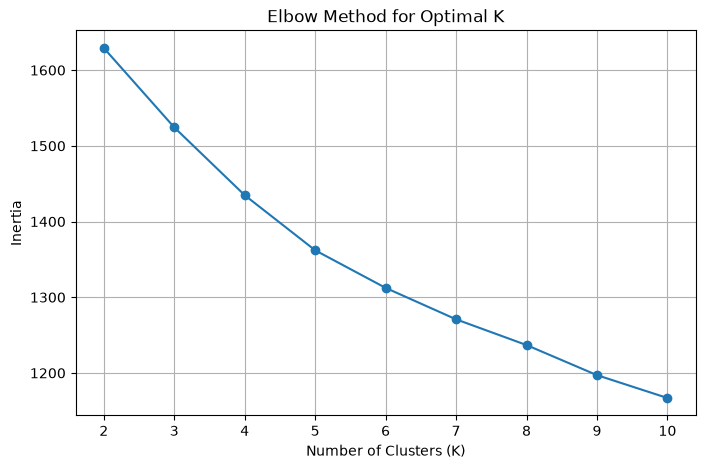

In [102]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [103]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_pca)
    
    score = silhouette_score(X_pca, cluster_labels)
    silhouette_scores.append(score)

print("Silhouette Scores:")

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: {score:.4f}")

c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Silhouette Scores:
K=2: 0.0742
K=3: 0.0713
K=4: 0.0757
K=5: 0.0775
K=6: 0.0797
K=7: 0.0744
K=8: 0.0728
K=9: 0.0710
K=10: 0.0760


c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [104]:
from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_pca)

print("Cluster labels:")
print(cluster_labels)

Cluster labels:
[1 1 5 4 4 3 0 0 4 1 0 3 1 5 5 4 0 0 5 2 5 3 4 1 3 0 4 0 0 1 2 0 3 5 1 5 1
 5 1 3 4 1 1 3 4 0 2 2 3 3 5 2 5 3 5 5 4 1 5 4 4 2 0 3 1 5 1 1 5 0 0 2 3 0
 5 5 4 5 4 2 3 3 4 3 0 3 0 3 1 3 4 0 2 2 2 1 3 1 5 3 4 5 5 5 5 4 4 0 4 1 3
 2 1 3 0 2 3 3 0 1 0 1 5 5 0 1 1 2 5 1 1 3 5 4 5 0 3 2 1 4 4 3 0 5 0 1 4 0
 5 5 2 5 4 5 5 4 0 4 0 4 5 4 1 1 0 1 4 2 4 3 0 4 1 5 5 1 3 3 3 2 4 0 5 5]


c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [105]:
import pandas as pd

cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

Number of customers in each cluster:
0    31
1    33
2    18
3    31
4    32
5    39
Name: count, dtype: int64


# DBSCAN 

In [141]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors 

min_samples = 10

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_pca)

distances, indices = neighbors_fit.kneighbors(X_pca)

k_distances = distances[:, -1]

In [142]:
import numpy as np

k_distances = np.sort(k_distances)

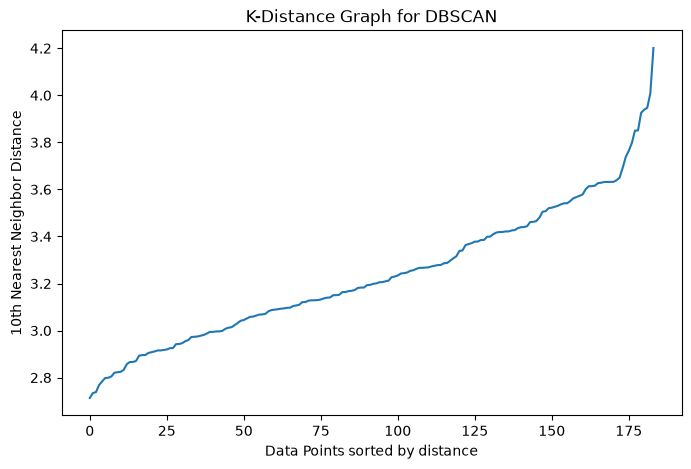

In [143]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(k_distances)

plt.xlabel("Data Points sorted by distance")
plt.ylabel("10th Nearest Neighbor Distance")
plt.title("K-Distance Graph for DBSCAN")

plt.show()

In [144]:
from sklearn.cluster import DBSCAN

db = DBSCAN(
    eps=3.65,
    min_samples=10
)

labels = db.fit_predict(X_pca)

In [145]:
unique_labels = set(labels)

n_clusters = len(unique_labels) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()

print("Unique labels:", unique_labels)
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Unique labels: {np.int64(0)}
Number of clusters: 1
Number of noise points: 0


In [146]:
from sklearn.cluster import DBSCAN
import pandas as pd

eps_values = [2.8, 3.0, 3.2, 3.4, 3.5]

results = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=10)
    labels = db.fit_predict(X_pca)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()

    results.append({
        "eps": eps,
        "clusters": n_clusters,
        "noise_points": n_noise
    })

results_df = pd.DataFrame(results)

print(results_df)

   eps  clusters  noise_points
0  2.8         2           129
1  3.0         1            55
2  3.2         1            23
3  3.4         1             4
4  3.5         1             1


In [147]:
eps_values = [2.2, 2.4, 2.6, 2.8]
min_samples_values = [3, 5, 7, 10]

In [148]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        db = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = db.fit_predict(X_pca)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        noise_pct = (n_noise / len(labels)) * 100

        # Silhouette requires at least 2 clusters
        if n_clusters >= 2:
            non_noise_mask = labels != -1

            if len(set(labels[non_noise_mask])) >= 2:
                silhouette = silhouette_score(
                    X_pca[non_noise_mask],
                    labels[non_noise_mask]
                )
            else:
                silhouette = None
        else:
            silhouette = None

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_points": n_noise,
            "noise_pct": noise_pct,
            "silhouette": silhouette
        })

results_df = pd.DataFrame(results)

results_df

,eps,min_samples,clusters,noise_points,noise_pct,silhouette
0,2.2,3,2,178,96.739130,0.301105
1,2.2,5,0,184,100.000000,NaN
2,2.2,7,0,184,100.000000,NaN
3,2.2,10,0,184,100.000000,NaN
4,2.4,3,4,156,84.782609,0.095803
5,2.4,5,0,184,100.000000,NaN
6,2.4,7,0,184,100.000000,NaN
7,2.4,10,0,184,100.000000,NaN
8,2.6,3,6,106,57.608696,0.027466
9,2.6,5,2,144,78.260870,0.079838
